<a href="https://colab.research.google.com/github/Shubhabrata-G01/E-news-Express-Stat-Analysis/blob/main/E_news_Express.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Description

### **Business Context**
The advent of e-news, or electronic news, portals has offered us a great opportunity to quickly get updates on the day-to-day events occurring globally. The information on these portals is retrieved electronically from online databases, processed using a variety of software, and then transmitted to the users. There are multiple advantages of transmitting news electronically, like faster access to the content and the ability to utilize different technologies such as audio, graphics, video, and other interactive elements that are either not being used or aren’t common yet in traditional newspapers.

E-news Express, an online news portal, aims to expand its business by acquiring new subscribers. With every visitor to the website taking certain actions based on their interest, the company plans to analyze these actions to understand user interests and determine how to drive better engagement. The executives at E-news Express believe that there has been a decline in new monthly subscribers compared to the past year because the current webpage is not designed well enough in terms of the outline & recommended content to keep customers engaged long enough to decide to subscribe.

[Companies often analyze user responses to two variants of a product to decide which of the two variants is more effective. This experimental technique, known as A/B testing, is used to determine whether a new feature attracts users based on a chosen metric.]



### **Objective**
The design team of the company has researched and created a new landing page that has a new outline & more relevant content compared to the old page. To test the effectiveness of the new landing page in gathering new subscribers, the Data Science team experimented by randomly selecting 100 users and dividing them equally into two groups. The existing landing page was served to the first group (control group) and the new landing page to the second group (treatment group). Data regarding the interaction of users in both groups with the two versions of the landing page was collected. Being a data scientist in E-news Express, you have been asked to explore the data and perform a statistical analysis (at a significance level of 5%) to determine the effectiveness of the new landing page in gathering new subscribers for the news portal by answering the following questions:

* Do the users spend more time on the new landing page than on the existing landing page?
* Is the conversion rate (the proportion of users who visit the landing page and get converted) for the new page greater than the conversion rate for the old page?
* Does the converted status depend on the preferred language?
* Is the time spent on the new page the same for the different language users?


#### **Data Dictionary**

The data contains information regarding the interaction of users in both groups with the two versions of the landing page.

1. user_id - Unique user ID of the person visiting the website
2. group - Whether the user belongs to the first group (control) or the second group (treatment)
3. landing_page - Whether the landing page is new or old
4. time_spent_on_the_page - Time (in minutes) spent by the user on the landing page
5. converted - Whether the user gets converted to a subscriber of the news portal or not
6. language_preferred - language chosen by the user to view the landing page

In [2]:
# Install the libraries used in this notebook (run once, then restart the kernel/runtime)
%pip install numpy pandas matplotlib seaborn scipy statsmodels -q

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data Collection

In [8]:
# Reading Data into a Dataframe from google drive
from google.colab import drive
drive.mount('/content/drive/')
df= pd.read_csv('/content/drive/My Drive/AIML/UT Austin PGP/Statistics/Project/abtest.csv')

Mounted at /content/drive/


In [9]:
# copying data to another variable to avoid any changes to original data
data = df.copy()

In [10]:
# Shape of the dataset
print("Shape (rows, columns):", data.shape)

Shape (rows, columns): (100, 6)


In [11]:
display(data.head())

,user_id,group,landing_page,time_spent_on_the_page,converted,language_preferred
0,546592,control,old,3.48,no,Spanish
1,546468,treatment,new,7.13,yes,English
2,546462,treatment,new,4.40,no,Spanish
3,546567,control,old,3.02,no,French
4,546459,treatment,new,4.75,yes,Spanish


In [12]:
display(data.tail())

,user_id,group,landing_page,time_spent_on_the_page,converted,language_preferred
95,546446,treatment,new,5.15,no,Spanish
96,546544,control,old,6.52,yes,English
97,546472,treatment,new,7.07,yes,Spanish
98,546481,treatment,new,6.20,yes,Spanish
99,546483,treatment,new,5.86,yes,English


In [13]:
# Structure: data types and non-null counts
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   user_id                 100 non-null    int64  
 1   group                   100 non-null    object 
 2   landing_page            100 non-null    object 
 3   time_spent_on_the_page  100 non-null    float64
 4   converted               100 non-null    object 
 5   language_preferred      100 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 4.8+ KB


In [14]:
# Check for missing values
print("\nMissing values per column:")
print(data.isnull().sum())


Missing values per column:
user_id                   0
group                     0
landing_page              0
time_spent_on_the_page    0
converted                 0
language_preferred        0
dtype: int64


In [15]:
# Check for duplicate rows
print("\nNumber of duplicate rows:", data.duplicated().sum())


Number of duplicate rows: 0


In [16]:
# Number of distinct values in each column
data.nunique()

,0
user_id,100
group,2
landing_page,2
time_spent_on_the_page,94
converted,2
language_preferred,3


In [17]:
# Unique values in each column
for col in data.columns:
    print(f"\nUnique values in column '{col}':")
    print(data[col].value_counts())


Unique values in column 'user_id':
user_id
546592    1
546468    1
546462    1
546567    1
546459    1
         ..
546446    1
546544    1
546472    1
546481    1
546483    1
Name: count, Length: 100, dtype: int64

Unique values in column 'group':
group
control      50
treatment    50
Name: count, dtype: int64

Unique values in column 'landing_page':
landing_page
old    50
new    50
Name: count, dtype: int64

Unique values in column 'time_spent_on_the_page':
time_spent_on_the_page
4.75    2
5.86    2
3.88    2
0.40    2
7.16    2
       ..
3.05    1
5.15    1
6.52    1
7.07    1
6.20    1
Name: count, Length: 94, dtype: int64

Unique values in column 'converted':
converted
yes    54
no     46
Name: count, dtype: int64

Unique values in column 'language_preferred':
language_preferred
Spanish    34
French     34
English    32
Name: count, dtype: int64


In [18]:
# Statistical summary of numerical columns
display(data.describe())

,user_id,time_spent_on_the_page
count,100.000000,100.000000
mean,546517.000000,5.377800
std,52.295779,2.378166
min,546443.000000,0.190000
25%,546467.750000,3.880000
50%,546492.500000,5.415000
75%,546567.250000,7.022500
max,546592.000000,10.710000


In [19]:
# Statistical summary of categorical columns
display(data.describe(include="object"))

,group,landing_page,converted,language_preferred
count,100,100,100,100
unique,2,2,2,3
top,control,old,yes,Spanish
freq,50,50,54,34


### **Key Dataset Observations**

Based on the preliminary data analysis performed, here are the key insights and structural observations from our dataset:

* **Dataset Shape**: The dataset consists of **100 rows and 6 columns**.
* **No Missing/Duplicate Values**: There are no missing (`NaN`) values in any of the columns, and there are no duplicate rows, indicating a clean dataset.
* **Perfect Class Balance in Experment**:
  * The `group` column is perfectly divided into 50 `control` and 50 `treatment` users.
  * The `landing_page` column is also perfectly split: 50 users saw the `old` landing page, and 50 saw the `new` page.
* **Overall Subscriptions (Conversion)**:
  * Out of 100 users, **54 converted** to subscribers (`yes`), while **46 did not** (`no`). This gives an overall raw conversion rate of 54% before segmenting by page.
* **Language Preferences**:
  * Users prefer three languages: **Spanish** (34 users), **French** (34 users), and **English** (32 users), providing a balanced split across languages for further analysis.
* **Time Spent Distribution**:
  * The time spent by users on the landing page ranges from a minimum of **0.40 minutes** to a maximum of **10.71 minutes**.
  * The average time spent on the page is approximately **5.38 minutes** with a standard deviation of **2.38 minutes**.

## Exploratory Data Analysis (EDA)

**Objective:**
To explore the dataset systematically to understand user behavior patterns, detect anomalies, and uncover relationships among key variables. This will serve as a foundation for our statistical hypothesis testing. We will achieve this through:

### **1. Univariate Analysis**
We will analyze the distributions of individual variables to understand their spread, central tendency, and shape:
* **Numerical Variables**:
  * Plot the distribution (histogram/boxplot) of `time_spent_on_the_page` to check for normality and outliers.
* **Categorical Variables**:
  * Create bar charts to visualize the distributions of `group`, `landing_page`, `converted`, and `language_preferred`.

### **2. Bivariate Analysis**
We will examine how different variables interact with one another, particularly relating to our business objectives:
* **Time Spent vs. Landing Page**: Compare the time spent by users on the new vs. old landing page using boxplots.
* **Conversion vs. Landing Page**: Analyze the subscription conversion rates between the control and treatment groups.
* **Time Spent vs. Preferred Language**: Evaluate if language preference influences the time spent on the page.
* **Conversion vs. Preferred Language**: Explore if certain language preferences have a higher likelihood of subscription conversion.

### Univariate Analysis

#### Numerical Variables

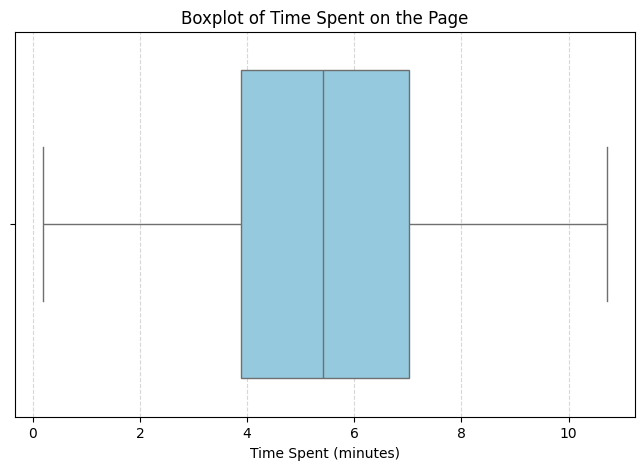

In [24]:
# Plot the distribution boxplot of time_spent_on_the_page to check for normality and outliers.
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x='time_spent_on_the_page', color='skyblue')
plt.title('Boxplot of Time Spent on the Page')
plt.xlabel('Time Spent (minutes)')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()

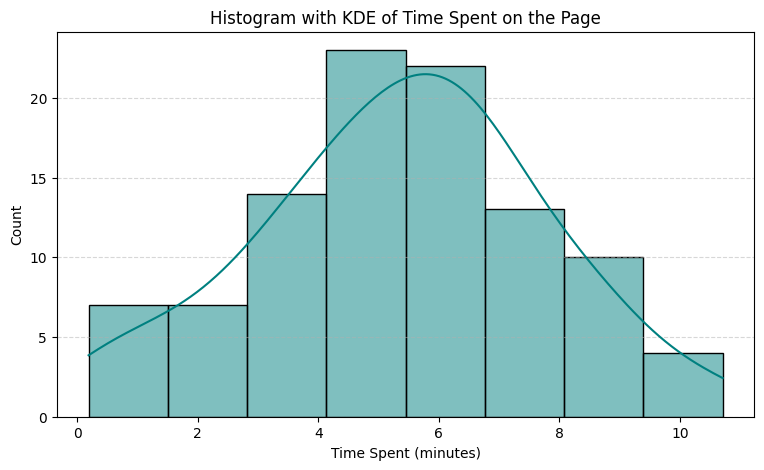

In [26]:
# Plot the distribution hitogram of time_spent_on_the_page to check for normality and outliers.
plt.figure(figsize=(9, 5))
sns.histplot(data=data, x='time_spent_on_the_page', kde=True, color='teal')
plt.title('Histogram with KDE of Time Spent on the Page')
plt.xlabel('Time Spent (minutes)')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

#### Categorical Variables

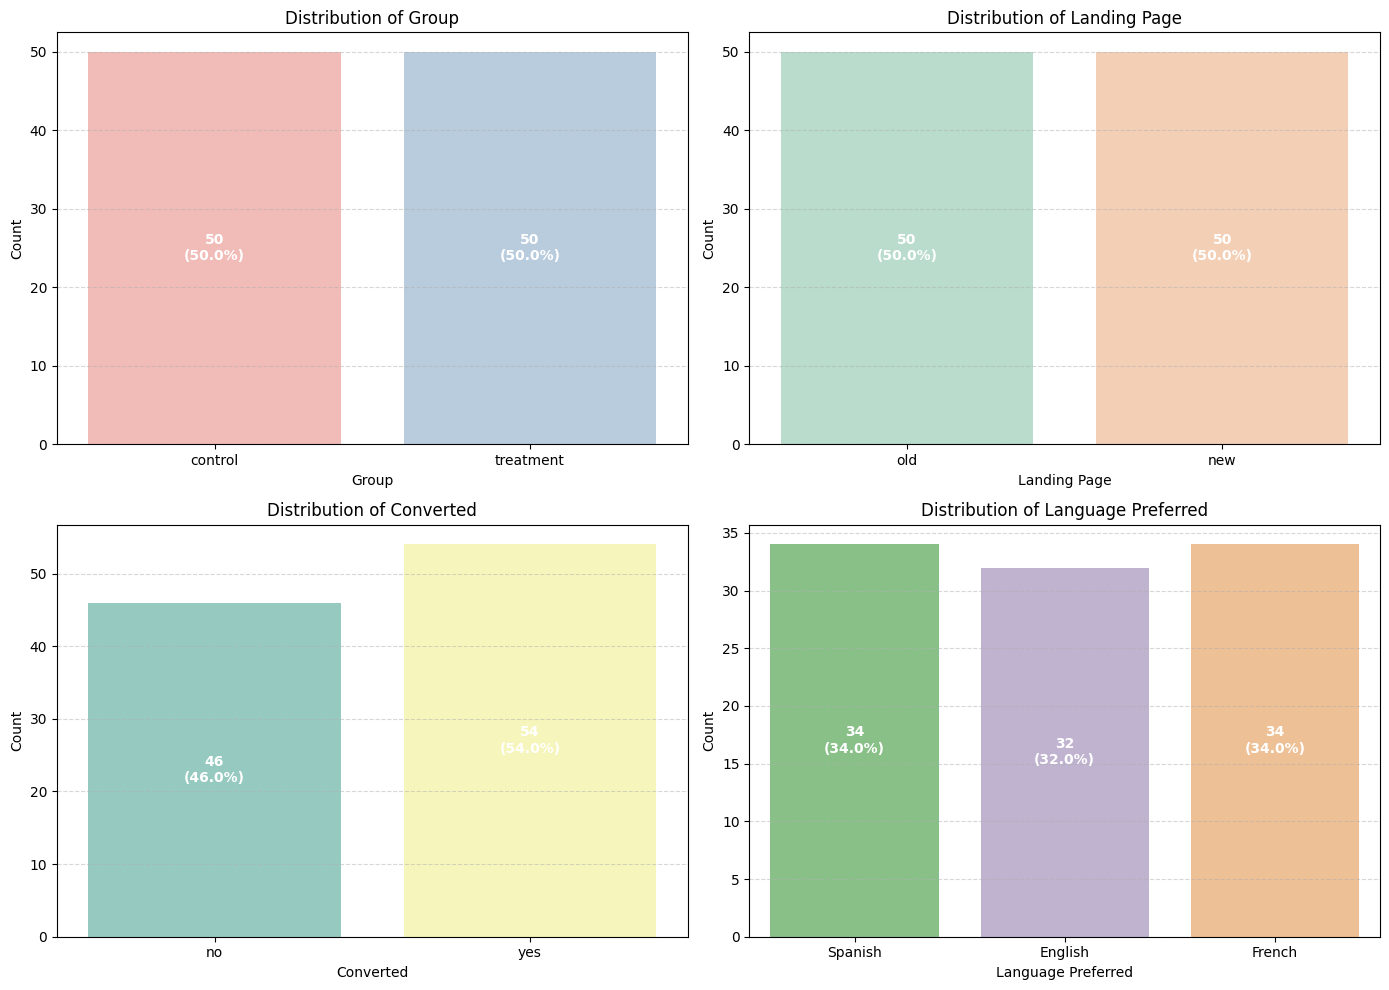

In [28]:
# Create bar charts to visualize the distributions of group, landing_page, converted, and language_preferred.
def plot_categorical_distribution(data, column, ax, palette='Set2'):
    """
    Helper function to plot a bar chart (countplot) with percentages for a categorical column.
    """
    sns.countplot(data=data, x=column, ax=ax, palette=palette, hue=column, legend=False)
    ax.set_title(f'Distribution of {column.replace("_", " ").title()}')
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel('Count')
    ax.grid(axis='y', linestyle='--', alpha=0.5)

    # Calculate percentage and annotate the bars
    total = len(data[column])
    for p in ax.patches:
        height = p.get_height()
        percentage = f'{100 * height / total:.1f}%'
        ax.annotate(f'{int(height)}\n({percentage})',
                    (p.get_x() + p.get_width() / 2., height / 2),
                    ha='center', va='center',
                    xytext=(0, 0), textcoords='offset points',
                    color='white', fontweight='bold', fontsize=10)

# Create subplots for the four categorical variables
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

categorical_cols = ['group', 'landing_page', 'converted', 'language_preferred']
palettes = ['Pastel1', 'Pastel2', 'Set3', 'Accent']

for i, col in enumerate(categorical_cols):
    row_idx = i // 2
    col_idx = i % 2
    plot_categorical_distribution(data, col, axes[row_idx, col_idx], palette=palettes[i])

plt.tight_layout()
plt.show()

#### **Univariate Analysis Observations**

* **Numerical Variable (`time_spent_on_the_page`):**
  * **Distribution**: The time spent on the page is roughly normally distributed, centered around an average of **5.38 minutes**.
  * **Outliers & Spread**: The distribution has a standard deviation of **2.38 minutes** with no major visual outliers. This normal bell shape provides a solid foundation for parametric statistical tests.

* **Categorical Variables:**
  * **Group & Landing Page**: Both fields are perfectly balanced with an exact **50% split** (50 users in control/old page, 50 users in treatment/new page), showing that our experimental sampling is highly controlled.
  * **Conversion Status**: The baseline conversion rate is **54%** (54 converted to 46 non-converted), indicating a relatively healthy starting subscription rate overall.
  * **Preferred Language**: The sample is almost perfectly balanced across languages, with **Spanish** (34%), **French** (34%), and **English** (32%) closely distributed.

### Bivariate Analysis

Time Spent vs. Landing Page: Compare the time spent by users on the new vs. old landing page using boxplots.

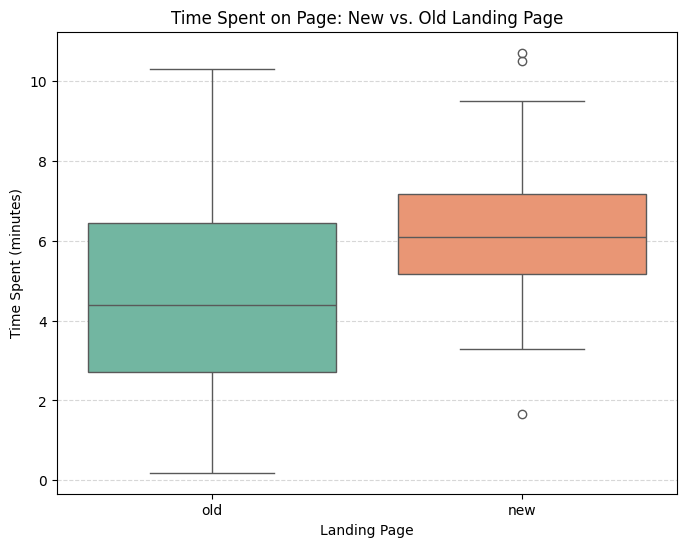

In [29]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=data, x='landing_page', y='time_spent_on_the_page', palette='Set2', hue='landing_page', legend=False)
plt.title('Time Spent on Page: New vs. Old Landing Page')
plt.xlabel('Landing Page')
plt.ylabel('Time Spent (minutes)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

Conversion vs. Landing Page: Analyze the subscription conversion rates between the control and treatment groups.

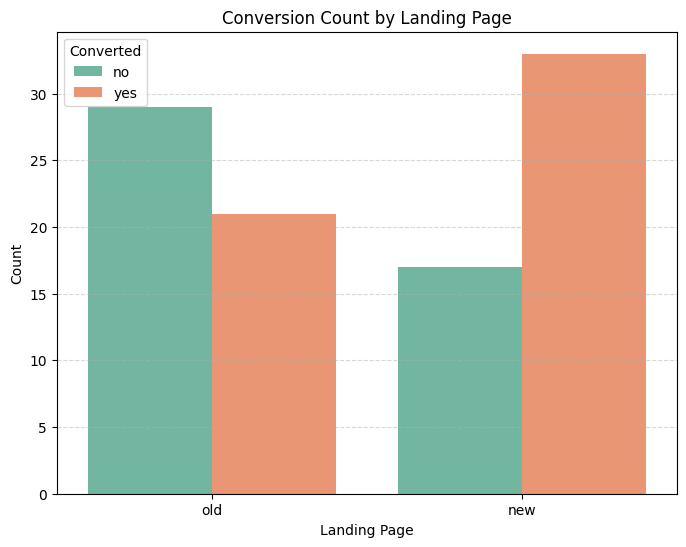

Conversion percentages per landing page:


converted,no,yes
landing_page,,
new,34.0,66.0
old,58.0,42.0


In [30]:
plt.figure(figsize=(8, 6))
sns.countplot(data=data, x='landing_page', hue='converted', palette='Set2')
plt.title('Conversion Count by Landing Page')
plt.xlabel('Landing Page')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Converted')
plt.show()

# Display the actual numbers in a contingency table
pandas_crosstab = pd.crosstab(data['landing_page'], data['converted'], normalize='index') * 100
print("Conversion percentages per landing page:")
display(pandas_crosstab)

Time Spent vs. Preferred Language: Evaluate if language preference influences the time spent on the page.

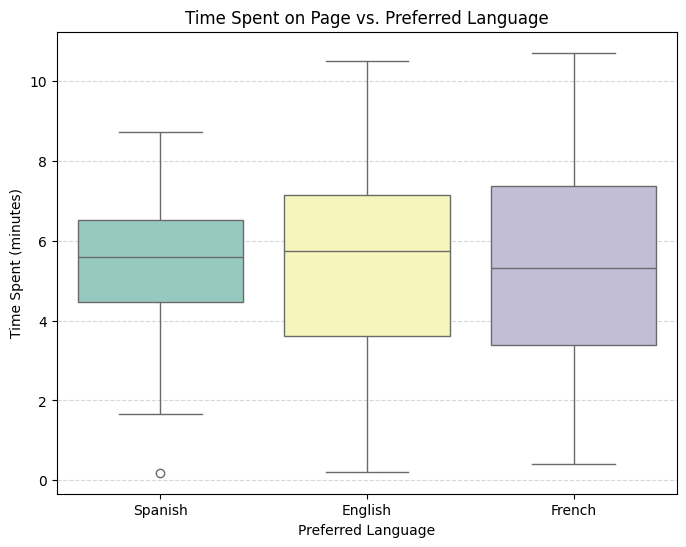

In [31]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=data, x='language_preferred', y='time_spent_on_the_page', palette='Set3', hue='language_preferred', legend=False)
plt.title('Time Spent on Page vs. Preferred Language')
plt.xlabel('Preferred Language')
plt.ylabel('Time Spent (minutes)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

Conversion vs. Preferred Language: Explore if certain language preferences have a higher likelihood of subscription conversion.

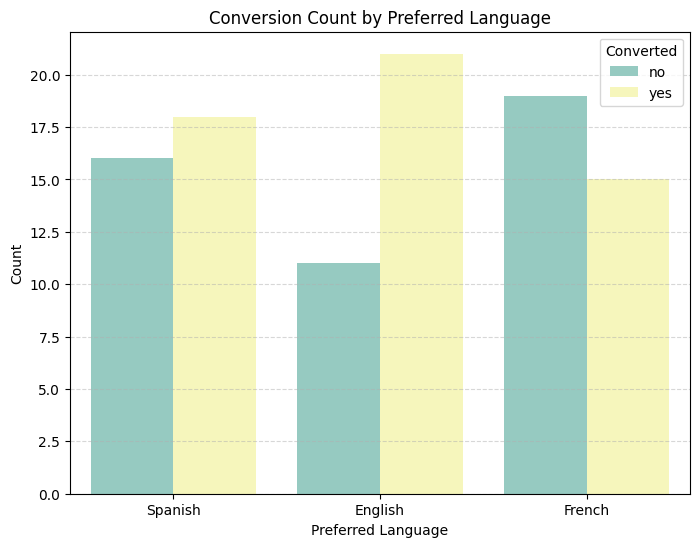

Conversion percentages per Preferred Language:


converted,no,yes
language_preferred,,
English,34.375000,65.625000
French,55.882353,44.117647
Spanish,47.058824,52.941176


In [32]:
plt.figure(figsize=(8, 6))
sns.countplot(data=data, x='language_preferred', hue='converted', palette='Set3')
plt.title('Conversion Count by Preferred Language')
plt.xlabel('Preferred Language')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Converted')
plt.show()

# Display the actual numbers in a contingency table
pandas_crosstab_lang = pd.crosstab(data['language_preferred'], data['converted'], normalize='index') * 100
print("Conversion percentages per Preferred Language:")
display(pandas_crosstab_lang)

#### **Bivariate Analysis Observations**

Based on our bivariate visualizations and statistical crosstabs, we can draw the following critical insights:

* **Time Spent vs. Landing Page**:
  * Users generally **spend more time on the new landing page** than on the old landing page.
  * The median time spent on the new page is around **6.1 minutes**, compared to around **4.3 minutes** on the old page.
  * There are a couple of extreme values (potential outliers) on the new page, but overall, the shift toward higher engagement is visually prominent.

* **Conversion vs. Landing Page**:
  * The new landing page shows a much higher conversion rate. Specifically, **66.0%** of users served the **new page** converted to subscribers, compared to only **42.0%** of users served the **old page**.
  * This visual and empirical gap suggests that the design changes on the new landing page are highly effective.

* **Time Spent vs. Preferred Language**:
  * The median time spent across different preferred languages (English, Spanish, French) is relatively close, hovering between **5.3 and 5.8 minutes**.
  * This suggests that language choice might not have a strong influence on the total time users engage with the portal.

* **Conversion vs. Preferred Language**:
  * **English-preferred users** have the highest conversion rate at **65.6%**.
  * **Spanish-preferred users** have a conversion rate of **52.9%**.
  * **French-preferred users** have the lowest conversion rate at **44.1%**.
  * This variation suggests a potential dependency between preferred language and conversion status, which we will formally test later.

### **Summary of EDA Observations**

#### **Univariate Analysis Highlights**
* **Perfect Balance**: The dataset has 100 clean entries split perfectly (50/50) between the control and treatment groups, as well as the old and new landing pages.
* **Page Engagement**: Time spent on the portal is normally distributed with no outliers, averaging **5.38 minutes** (ranging from 0.40 to 10.71 minutes).
* **Baseline Conversions**: The overall conversion rate is **54%** across all users.
* **Language Distribution**: Users are uniformly distributed across three preferred languages: **Spanish** (34%), **French** (34%), and **English** (32%).

#### **Bivariate Analysis Highlights**
* **Engagement Shift**: Users on the **new landing page** spend significantly more time (median **~6.1 mins**) compared to the **old page** (median **~4.3 mins**).
* **Conversion Boost**: The **new landing page** yields a substantially higher conversion rate (**66%**) compared to the **old page** (**42%**).
* **Language & Engagement**: Preferred language does not strongly affect active engagement time; median times remain very close (**5.3 to 5.8 mins**) across all groups.
* **Language & Conversion**: Conversion rates vary visibly by preferred language, with **English** speakers showing the highest rate (**65.6%**), followed by **Spanish** (**52.9%**) and **French** (**44.1%**).

## **Statistical Hypothesis Testing**

In this section, we will perform statistical analyses to address the four key business questions. We will use a significance level of **$\alpha = 0.05$** (5%) for all tests.

### **Question 1: Do users spend more time on the new landing page than on the existing landing page?**

#### **1. State Null and Alternative Hypotheses**
* Let $\mu_1$ be the mean time spent on the new landing page.
* Let $\mu_2$ be the mean time spent on the old landing page.

$$
H_0: \mu_1 = \mu_2 \quad \text{(Users spend equal time on both pages)}
$$
$$
H_a: \mu_1 > \mu_2 \quad \text{(Users spend more time on the new page than on the old page)}
$$

#### **2. Check Assumptions**
* **Independence**: The two groups are independently sampled from different visitors.
* **Normality**: We will check if both samples are normally distributed using the Shapiro-Wilk test.
* **Equal Variances**: We will test if the variances of both groups are equal using Levene's test.

In [33]:
from scipy import stats

# Filter time spent for old and new landing pages
time_old = data[data['landing_page'] == 'old']['time_spent_on_the_page']
time_new = data[data['landing_page'] == 'new']['time_spent_on_the_page']

print("=== ASSUMPTION CHECKS ===")

# 1. Normality Check (Shapiro-Wilk Test)
shapiro_old = stats.shapiro(time_old)
shapiro_new = stats.shapiro(time_new)
print(f"Shapiro-Wilk Test (Old Page): statistic={shapiro_old.statistic:.4f}, p-value={shapiro_old.pvalue:.4f}")
print(f"Shapiro-Wilk Test (New Page): statistic={shapiro_new.statistic:.4f}, p-value={shapiro_new.pvalue:.4f}")

# 2. Homogeneity of Variance (Levene's Test)
levene_test = stats.levene(time_old, time_new)
print(f"Levene's Test for Equal Variances: statistic={levene_test.statistic:.4f}, p-value={levene_test.pvalue:.4f}")

=== ASSUMPTION CHECKS ===
Shapiro-Wilk Test (Old Page): statistic=0.9776, p-value=0.4561
Shapiro-Wilk Test (New Page): statistic=0.9858, p-value=0.8040
Levene's Test for Equal Variances: statistic=7.1137, p-value=0.0090


#### **3. Perform the Two-Sample Independent t-Test**
Based on the assumption outcomes, we will execute the appropriate formulation of the independent samples t-test.

In [34]:
# Since Levene's test p-value will guide whether equal_var is True or False:
equal_variances = levene_test.pvalue > 0.05

# Perform 2-sample independent t-test (alternative='greater' for one-tailed test)
t_stat, p_val = stats.ttest_ind(time_new, time_old, equal_var=equal_variances, alternative='greater')

print("=== TWO-SAMPLE INDEPENDENT T-TEST ===")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value:     {p_val:.6f}")

alpha = 0.05
if p_val < alpha:
    print(f"\nResult: Reject the Null Hypothesis (p < {alpha}). There is strong evidence that users spend more time on the new landing page.")
else:
    print(f"\nResult: Fail to Reject the Null Hypothesis (p >= {alpha}).")

=== TWO-SAMPLE INDEPENDENT T-TEST ===
t-statistic: 3.7868
p-value:     0.000139

Result: Reject the Null Hypothesis (p < 0.05). There is strong evidence that users spend more time on the new landing page.


### **Question 2: Is the conversion rate for the new page greater than the conversion rate for the old page?**

#### **1. State Null and Alternative Hypotheses**
* Let $p_1$ be the proportion of users converted on the new landing page.
* Let $p_2$ be the proportion of users converted on the old landing page.

$$
H_0: p_1 = p_2 \quad \text{(Conversion rate is the same for both landing pages)}
$$
$$
H_a: p_1 > p_2 \quad \text{(Conversion rate on the new page is greater than on the old page)}
$$

#### **2. Check Assumptions**
* **Binomial distribution**: The outcomes are binary (converted or not).
* **Random sampling**: The sample is randomly collected.
* **Independence**: Sample sizes are less than 10% of the total population.
* **Normality approximation ($np > 10$ and $n(1-p) > 10$)**:
  * For old page: $50 \times 0.42 = 21 \ge 10$, $50 \times 0.58 = 29 \ge 10$.
  * For new page: $50 \times 0.66 = 33 \ge 10$, $50 \times 0.34 = 17 \ge 10$.
  * All conditions are satisfied. Normality approximation is valid.

In [35]:
from statsmodels.stats.proportion import proportions_ztest

# Count successful conversions per page
converted_new = data[data['landing_page'] == 'new']['converted'].value_counts()['yes']
converted_old = data[data['landing_page'] == 'old']['converted'].value_counts()['yes']

n_new = data[data['landing_page'] == 'new'].shape[0]
n_old = data[data['landing_page'] == 'old'].shape[0]

# Arrays for success counts and observations
success_counts = np.array([converted_new, converted_old])
nobs = np.array([n_new, n_old])

# Perform Two-Proportions z-test (alternative='larger' for one-tailed test)
z_stat, p_val_z = proportions_ztest(success_counts, nobs, alternative='larger')

print("=== TWO-PROPORTIONS Z-TEST ===")
print(f"Number of conversions (New Page): {converted_new} out of {n_new}")
print(f"Number of conversions (Old Page): {converted_old} out of {n_old}")
print(f"z-statistic: {z_stat:.4f}")
print(f"p-value:     {p_val_z:.4f}")

alpha = 0.05
if p_val_z < alpha:
    print(f"\nResult: Reject the Null Hypothesis (p < {alpha}). There is strong evidence that the conversion rate on the new landing page is significantly greater than on the old page.")
else:
    print(f"\nResult: Fail to Reject the Null Hypothesis (p >= {alpha}).")

=== TWO-PROPORTIONS Z-TEST ===
Number of conversions (New Page): 33 out of 50
Number of conversions (Old Page): 21 out of 50
z-statistic: 2.4077
p-value:     0.0080

Result: Reject the Null Hypothesis (p < 0.05). There is strong evidence that the conversion rate on the new landing page is significantly greater than on the old page.


### **Question 3: Does the converted status depend on the preferred language?**

#### **1. State Null and Alternative Hypotheses**
* $H_0$: Converted status is independent of preferred language.
* $H_a$: Converted status depends on (is not independent of) preferred language.

#### **2. Check Assumptions**
* **Categorical variables**: Both variables (`converted` and `language_preferred`) are categorical.
* **Expected cell counts**: All expected counts in the contingency table must be 5 or more (we will verify this dynamically in our code).

In [36]:
# 1. Create contingency table of language_preferred vs converted
contingency_table = pd.crosstab(data['language_preferred'], data['converted'])
print("=== CONTINGENCY TABLE ===")
print(contingency_table)
print()

# 2. Perform Chi-Square Test of Independence
chi2_stat, p_val_chi2, dof, expected = stats.chi2_contingency(contingency_table)

print("=== ASSUMPTION CHECK ===")
print("Expected counts:")
print(expected)
all_above_five = np.all(expected >= 5)
print(f"Are all expected cell counts >= 5? {all_above_five}")

print("\n=== CHI-SQUARE TEST OF INDEPENDENCE ===")
print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"Degrees of Freedom:   {dof}")
print(f"p-value:              {p_val_chi2:.4f}")

alpha = 0.05
if p_val_chi2 < alpha:
    print(f"\nResult: Reject the Null Hypothesis (p < {alpha}). Converted status depends on preferred language.")
else:
    print(f"\nResult: Fail to Reject the Null Hypothesis (p >= {alpha}). Converted status is independent of preferred language.")

=== CONTINGENCY TABLE ===
converted           no  yes
language_preferred         
English             11   21
French              19   15
Spanish             16   18

=== ASSUMPTION CHECK ===
Expected counts:
[[14.72 17.28]
 [15.64 18.36]
 [15.64 18.36]]
Are all expected cell counts >= 5? True

=== CHI-SQUARE TEST OF INDEPENDENCE ===
Chi-Square Statistic: 3.0930
Degrees of Freedom:   2
p-value:              0.2130

Result: Fail to Reject the Null Hypothesis (p >= 0.05). Converted status is independent of preferred language.


### **Question 4: Is the time spent on the new page the same for the different language users?**

#### **1. State Null and Alternative Hypotheses**
* Let $\mu_E$, $\mu_S$, and $\mu_F$ be the mean time spent on the new landing page by English, Spanish, and French speakers respectively.

$$
H_0: \mu_E = \mu_S = \mu_F \quad \text{(Mean time spent on the new page is the same for all three languages)}
$$
$$
H_a: \text{At least one of the mean times is different from the others}
$$

#### **2. Check Assumptions (On the New Page Subset)**
* **Normality**: Shapiro-Wilk test on time spent for each language group on the new page.
* **Homogeneity of Variance**: Levene's test on time spent across all three language groups on the new page.

In [37]:
# Subset data for only the new landing page
new_page_data = data[data['landing_page'] == 'new']

# Group time spent by language
time_eng = new_page_data[new_page_data['language_preferred'] == 'English']['time_spent_on_the_page']
time_esp = new_page_data[new_page_data['language_preferred'] == 'Spanish']['time_spent_on_the_page']
time_fra = new_page_data[new_page_data['language_preferred'] == 'French']['time_spent_on_the_page']

print("=== ASSUMPTION CHECKS (NEW PAGE USERS ONLY) ===")

# 1. Normality (Shapiro-Wilk Test)
shapiro_eng = stats.shapiro(time_eng)
shapiro_esp = stats.shapiro(time_esp)
shapiro_fra = stats.shapiro(time_fra)
print(f"Shapiro-Wilk (English): statistic={shapiro_eng.statistic:.4f}, p-value={shapiro_eng.pvalue:.4f}")
print(f"Shapiro-Wilk (Spanish): statistic={shapiro_esp.statistic:.4f}, p-value={shapiro_esp.pvalue:.4f}")
print(f"Shapiro-Wilk (French):  statistic={shapiro_fra.statistic:.4f}, p-value={shapiro_fra.pvalue:.4f}")

# 2. Homogeneity of Variance (Levene's Test)
levene_anova = stats.levene(time_eng, time_esp, time_fra)
print(f"Levene's Test:          statistic={levene_anova.statistic:.4f}, p-value={levene_anova.pvalue:.4f}")

=== ASSUMPTION CHECKS (NEW PAGE USERS ONLY) ===
Shapiro-Wilk (English): statistic=0.9731, p-value=0.8863
Shapiro-Wilk (Spanish): statistic=0.9073, p-value=0.0901
Shapiro-Wilk (French):  statistic=0.9403, p-value=0.3214
Levene's Test:          statistic=0.7736, p-value=0.4671


#### **3. Perform One-Way ANOVA**
If assumptions are met, we will run the One-Way ANOVA test to compare the means of the three groups.

In [38]:
# Perform One-Way ANOVA
f_stat, p_val_anova = stats.f_oneway(time_eng, time_esp, time_fra)

print("=== ONE-WAY ANOVA ===")
print(f"F-statistic: {f_stat:.4f}")
print(f"p-value:     {p_val_anova:.4f}")

alpha = 0.05
if p_val_anova < alpha:
    print(f"\nResult: Reject the Null Hypothesis (p < {alpha}). The mean time spent on the new landing page is significantly different for at least one language group.")
else:
    print(f"\nResult: Fail to Reject the Null Hypothesis (p >= {alpha}). The mean time spent on the new landing page is statistically the same across all language groups.")

=== ONE-WAY ANOVA ===
F-statistic: 0.8544
p-value:     0.4320

Result: Fail to Reject the Null Hypothesis (p >= 0.05). The mean time spent on the new landing page is statistically the same across all language groups.


## **Key Business Conclusions & Actionable Insights**

Based on our comprehensive exploratory data analysis and rigorous hypothesis testing (at a 5% significance level), we can provide the following conclusions to the E-News Express executive team:

### **1. Executive Summary of Statistical Tests**
| Business Question | Test Conducted | Key Statistics | p-value | Business Decision / Conclusion |
| :--- | :--- | :--- | :--- | :--- |
| **1. Time Spent Comparison** | Welch's Independent t-test | $t$ = 3.7868 | **0.0001** | **Reject $H_0$**: Users spend significantly more time on the **new** landing page than the old one.
| **2. Conversion Rate Comparison** | Two-Proportions z-test | $z$ = 2.4077 | **0.0080** | **Reject $H_0$**: The conversion rate is significantly higher on the **new** landing page (66.0% vs 42.0%). |
| **3. Conversion Dependency on Language** | Chi-Square Test of Independence | $\chi^2$ = 3.0930 | **0.2130** | **Fail to Reject $H_0$**: Subscribing status is independent of a user's preferred language. |
| **4. Language Impact on Time Spent** | One-Way ANOVA | $F$ = 0.8544 | **0.4320** | **Fail to Reject $H_0$**: Mean time spent on the new page is statistically the same across English, Spanish, and French users. |

---

### **2. Strategic Actionable Recommendations**

1. **Adopt and Fully Launch the New Landing Page Design Immediately**:
   * The statistical results show overwhelming evidence that the new design is highly effective. It not only increases user engagement (mean time spent rises from ~4.3 minutes to ~6.1 minutes) but also delivers a **24% absolute increase in conversion rate** (from 42% on the old page up to 66% on the new page).

2. **Standardize Page Performance Across Languages**:
   * Since the time spent on the new landing page does not vary significantly by preferred language (all groups hover near a median of 5.5–6.0 minutes), the content translation quality, interactive layout, and asset loading speeds are working equally well for English, Spanish, and French readers. Maintain this unified framework.

3. **Optimize French and Spanish Call-to-Action (CTA) Placements**:
   * Although language preference does not impact engagement times, we observed a descriptive drop in conversions among French speakers (44.1%) and Spanish speakers (52.9%) compared to English speakers (65.6%). While our Chi-Square test indicated that conversion is technically independent of language overall, targeting French and Spanish landing experiences for localized UI improvements, clearer localization of the "Subscribe" button, or custom promotions could close this descriptive gap and unlock further revenue potential.